In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import lgamma

## Задание 1. Закон всемирного тяготения

Используем метод для вычисления силы взаимного притяжения Луны и Земли. Для простоты предположим, что плотности Земли и Луны не зависят от координат и возьмем их средние значения. Для проведения численного эксперимента нам понадобятся следующие физические величины:

$$G = 6.67 \cdot 10^{-11} \frac{\text{Н} \cdot \text{м}^2}{\text{кг}^2} \text{ — гравитационная постоянная;}$$
$$m_1 = 6 \cdot 10^{24} \text{ кг} \text{ — масса Земли;}$$
$$m_2 = 7.35 \cdot 10^{22} \text{ кг} \text{ — масса Луны;}$$
$$r = 384467000 \text{ м} \text{ — расстояние между Луной и Землей;}$$
$$\rho_1 = 5520 \frac{\text{кг}}{\text{м}^3} \text{ — средняя плотность Земли;}$$
$$\rho_2 = 3346 \frac{\text{кг}}{\text{м}^3} \text{ — средняя плотность Луны;}$$
$$R_1 = 6367000 \text{ м} \text{ — радиус Земли;}$$
$$R_2 = 1737000 \text{ м} \text{ — радиус Луны.}$$

Поскольку тела сферические со сферически симметричной функцией плотности (константой), то объекты можно рассматривать как точечные и вычислить их силу притяжения по формуле:

$$F = G \frac{m_1 \cdot m_2}{r^2},$$

где $m_1$ и $m_2$ массы точечных объектов. Это значение будем использовать для сравнения с результатами вычислений с помощью метода Монте-Карло. По формуле находим значение силы

$$F = 1.98997 \cdot 10^{20} \text{ Н}.$$

Результаты вычислений этой силы с помощью метода Монте-Карло и аналитически сравнить между собой. Построить график зависимости ошибки от числа итераций в логарифмическом масштабе, сделать вывод об асимптотике ошибки.

In [2]:
G = 6.67e-11

m1 = 6.0e24
m2 = 7.35e22
r = 384_467_000.0

R1 = 6_367_000.0
R2 = 1_737_000.0

rho1_given = 5520.0
rho2_given = 3346.0

V1 = 4 * np.pi * R1**3 / 3
V2 = 4 * np.pi * R2**3 / 3

rho1 = m1 / V1
rho2 = m2 / V2

F_exact = G * m1 * m2 / r**2
F_exact_by_given_rho = G * (rho1_given * V1) * (rho2_given * V2) / r**2

print(f"F_exact = {F_exact:.5e} Н")
print(f"F_exact_by_given_rho = {F_exact_by_given_rho:.5e} Н")
print(f"rho1_eff = {rho1:.2f} кг/м^3")
print(f"rho2_eff = {rho2:.2f} кг/м^3")

rng = np.random.default_rng(1337)

earth_center = np.array([0.0, 0.0, 0.0])
moon_center = np.array([r, 0.0, 0.0])

factor = G * rho1 * rho2 * V1 * V2

def sample_ball(n, R, center, rng):
    direction = rng.normal(size=(n, 3))
    direction /= np.linalg.norm(direction, axis=1)[:, None]
    radius = R * rng.random(n)[:, None]**(1 / 3)
    return center + radius * direction


def force_mc(n, rng):
    x1 = sample_ball(n, R1, earth_center, rng)
    x2 = sample_ball(n, R2, moon_center, rng)

    d = x2 - x1
    dist2 = np.sum(d * d, axis=1)
    kernel = d[:, 0] / (dist2 * np.sqrt(dist2))

    return factor * np.mean(kernel)

N_test = 200_000

F_mc = force_mc(N_test, rng)
rel_error = abs(F_mc - F_exact) / F_exact

print(f"N = {N_test}")
print(f"F_mc = {F_mc:.5e} Н")
print(f"F_exact = {F_exact:.5e} Н")
print(f"relative error = {rel_error:.5e}")



F_exact = 1.98997e+20 Н
F_exact_by_given_rho = 1.97813e+20 Н
rho1_eff = 5549.55 кг/м^3
rho2_eff = 3348.11 кг/м^3
N = 200000
F_mc = 1.98995e+20 Н
F_exact = 1.98997e+20 Н
relative error = 9.74687e-06


slope = -0.493


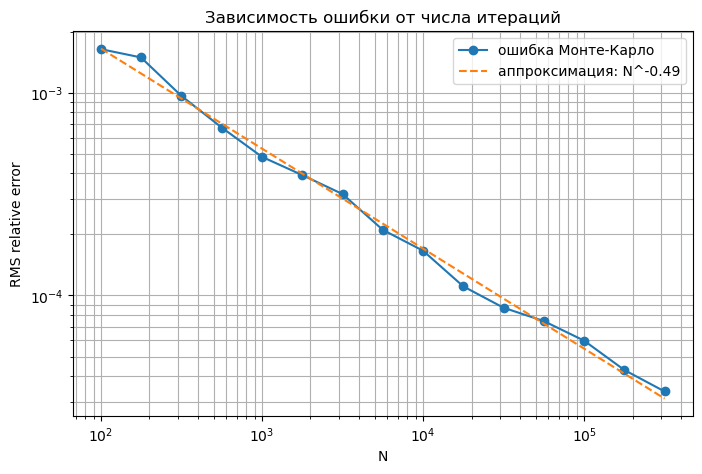

In [3]:

def force_mc_curve(n_values, rng):
    n_max = int(np.max(n_values))

    x1 = sample_ball(n_max, R1, earth_center, rng)
    x2 = sample_ball(n_max, R2, moon_center, rng)

    d = x2 - x1
    dist2 = np.sum(d * d, axis=1)
    kernel = d[:, 0] / (dist2 * np.sqrt(dist2))

    sums = np.cumsum(kernel)
    return factor * sums[n_values - 1] / n_values


N_values = np.unique(np.logspace(2, 5.5, 15).astype(int))
M = 40

forces = np.array([force_mc_curve(N_values, rng) for _ in range(M)])
rel_errors = np.sqrt(np.mean(((forces - F_exact) / F_exact)**2, axis=0))

slope, intercept = np.polyfit(np.log(N_values), np.log(rel_errors), 1)

print(f"slope = {slope:.3f}")

plt.figure(figsize=(8, 5))

plt.loglog(N_values, rel_errors, "o-", label="ошибка Монте-Карло")
plt.loglog(
    N_values,
    np.exp(intercept) * N_values**slope,
    "--",
    label=f"аппроксимация: N^{slope:.2f}"
)

plt.xlabel("N")
plt.ylabel("RMS relative error")
plt.title("Зависимость ошибки от числа итераций")
plt.grid(True, which="both")
plt.legend()
plt.show()

### Вывод

В методе Монте-Карло Земля и Луна рассматривались как два шара с постоянной плотностью. На каждой итерации случайно выбиралась одна точка внутри Земли и одна точка внутри Луны, после чего вычислялся вклад силы притяжения между соответствующими малыми элементами масс.
Асимптотика ошибки имеет вид

$$
\varepsilon_N = O\left(\frac{1}{\sqrt{N}}\right).
$$

## Задание 2. Закон всемирного тяготения

Пусть на однородную пластинку бесконечной площади толщиной $h$ нормально падает поток нейтронов с энергией $E_0$. При столкновении с атомами вещества, из которого состоит пластинка, нейтроны могут: а) упруго рассеиваться; б) поглощаться. Пусть при упругом рассеянии: энергия не меняется; равновероятно любое направление рассеяния. Сечения поглощения и сечения рассеяния нейтронов считать известными. Требуется вычислить:

* вероятность прохождения нейтрона сквозь пластинку $P_+$,
* вероятность отражения нейтронов от пластинки $P_-$,
* вероятность поглощения нейтрона в пластинке $P_O$.

In [4]:
h = 0.05

n_atoms = 5e28
sigma_abs = 0.2e-28
sigma_scat = 2.0e-28

Sigma_abs = n_atoms * sigma_abs
Sigma_scat = n_atoms * sigma_scat
Sigma_total = Sigma_abs + Sigma_scat

N = 200_000
rng = np.random.default_rng(1337)

print(f"Sigma_abs = {Sigma_abs:.3f} 1/м")
print(f"Sigma_scat = {Sigma_scat:.3f} 1/м")
print(f"lambda = {1 / Sigma_total:.5f} м")

def simulate_neutrons(N, h, Sigma_abs, Sigma_scat, rng, max_steps=10000):
    Sigma_total = Sigma_abs + Sigma_scat
    p_abs = Sigma_abs / Sigma_total

    z = np.zeros(N)
    mu = np.ones(N)
    status = np.zeros(N, dtype=int)
    active = np.ones(N, dtype=bool)

    step = 0

    while np.any(active) and step < max_steps:
        idx = np.where(active)[0]
        s = rng.exponential(1 / Sigma_total, size=len(idx))

        z_new = z[idx] + mu[idx] * s

        passed = z_new >= h
        reflected = z_new <= 0
        collided = ~(passed | reflected)

        status[idx[passed]] = 1
        status[idx[reflected]] = -1
        active[idx[passed | reflected]] = False

        idx_col = idx[collided]

        if len(idx_col) > 0:
            z[idx_col] = z_new[collided]

            absorbed = rng.random(len(idx_col)) < p_abs
            status[idx_col[absorbed]] = 2
            active[idx_col[absorbed]] = False

            idx_scat = idx_col[~absorbed]
            mu[idx_scat] = rng.uniform(-1, 1, size=len(idx_scat))

        step += 1

    return status


status = simulate_neutrons(N, h, Sigma_abs, Sigma_scat, rng)

P_plus = np.mean(status == 1)
P_minus = np.mean(status == -1)
P_0 = np.mean(status == 2)

err_plus = np.sqrt(P_plus * (1 - P_plus) / N)
err_minus = np.sqrt(P_minus * (1 - P_minus) / N)
err_0 = np.sqrt(P_0 * (1 - P_0) / N)

print(f"P_+ = {P_plus:.5f} ± {err_plus:.5f}")
print(f"P_- = {P_minus:.5f} ± {err_minus:.5f}")
print(f"P_0 = {P_0:.5f} ± {err_0:.5f}")
print(f"sum = {P_plus + P_minus + P_0:.5f}")

Sigma_abs = 1.000 1/м
Sigma_scat = 10.000 1/м
lambda = 0.09091 м
P_+ = 0.74677 ± 0.00097
P_- = 0.18660 ± 0.00087
P_0 = 0.06662 ± 0.00056
sum = 1.00000


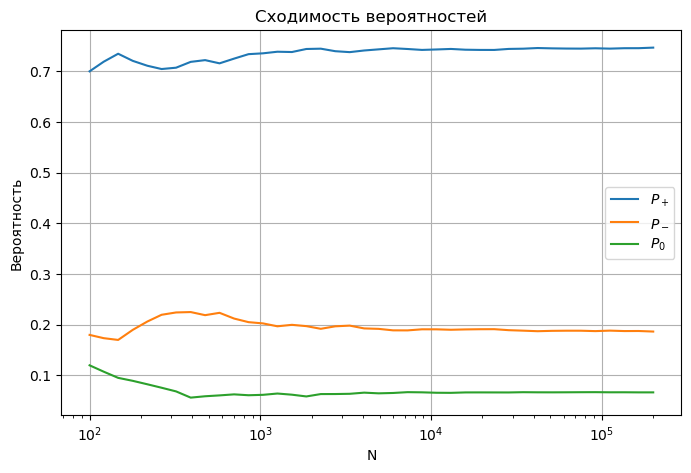

In [5]:
N_values = np.unique(np.logspace(2, np.log10(N), 40).astype(int))

P_plus_curve = []
P_minus_curve = []
P_0_curve = []

for n in N_values:
    part = status[:n]

    P_plus_curve.append(np.mean(part == 1))
    P_minus_curve.append(np.mean(part == -1))
    P_0_curve.append(np.mean(part == 2))

plt.figure(figsize=(8, 5))

plt.semilogx(N_values, P_plus_curve, label="$P_+$")
plt.semilogx(N_values, P_minus_curve, label="$P_-$")
plt.semilogx(N_values, P_0_curve, label="$P_0$")

plt.xlabel("N")
plt.ylabel("Вероятность")
plt.title("Сходимость вероятностей")
plt.grid(True)
plt.legend()
plt.show()

На каждом шаге случайно выбиралась длина свободного пробега до следующего столкновения. Если нейтрон выходил за правую границу пластинки, он засчитывался как прошедший. Если выходил за левую границу, он засчитывался как отражённый. Если происходило столкновение внутри пластинки, нейтрон либо поглощался, либо упруго рассеивался в случайном направлении.

Проверка показывает, что $P_+ + P_- + P_0 \approx 1$, то есть все возможные исходы учтены.

## Задание 3. Случайное блуждание

Рассмотрим одномерное случайное блуждание, где на каждом шаге с вероятностью $1/2$ точка движется влево или вправо на единицу длины. Чему равно математическое ожидание расстояния точки от нуля после $T$ шагов?

Вычислите аналитически, затем промоделируйте численно.

Проанализируйте погрешность (нарисовать график и гистограмму).

### Аналитическое решение

Пусть $S_T$ — положение точки после $T$ шагов. На каждом шаге точка с вероятностью $1/2$ идёт вправо и с вероятностью $1/2$ влево.

Если $K$ — число шагов вправо, то $K \sim Bin(T, 1/2)$, а конечная координата равна $S_T = 2K - T$.

Тогда расстояние от нуля равно $|S_T|$, поэтому

$E|S_T| = \sum_{k=0}^{T} |2k - T| \cdot \frac{C_T^k}{2^T}$.

При больших $T$ можно использовать приближение нормальным распределением:

$S_T \approx N(0, T)$,

поэтому

$E|S_T| \approx \sqrt{\frac{2T}{\pi}}$.

In [6]:
def exact_mean_distance(T):
    ans = 0.0

    for k in range(T + 1):
        log_p = lgamma(T + 1) - lgamma(k + 1) - lgamma(T - k + 1) - T * np.log(2)
        p = np.exp(log_p)
        ans += abs(2 * k - T) * p

    return ans


def monte_carlo_distance(T, N, rng):
    k = rng.binomial(T, 0.5, size=N)
    distances = np.abs(2 * k - T)
    return distances.mean(), distances


T = 100
N = 100000

rng = np.random.default_rng(1337)

exact_value = exact_mean_distance(T)
mc_value, distances = monte_carlo_distance(T, N, rng)
asymptotic_value = np.sqrt(2 * T / np.pi)

print(f"T = {T}")
print(f"analytic = {exact_value:.6f}")
print(f"Monte Carlo = {mc_value:.6f}")
print(f"asymptotic = {asymptotic_value:.6f}")
print(f"absolute error = {abs(mc_value - exact_value):.6f}")

T = 100
analytic = 7.958924
Monte Carlo = 7.946540
asymptotic = 7.978846
absolute error = 0.012384


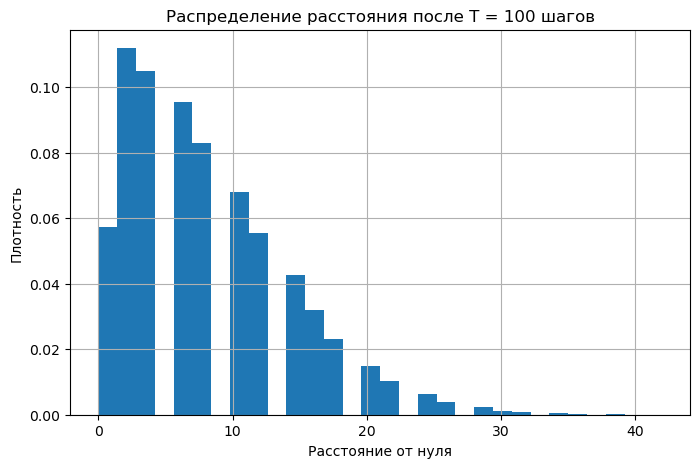

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(distances, bins=30, density=True)

plt.xlabel("Расстояние от нуля")
plt.ylabel("Плотность")
plt.title(f"Распределение расстояния после T = {T} шагов")
plt.grid(True)

plt.show()

slope = -0.498


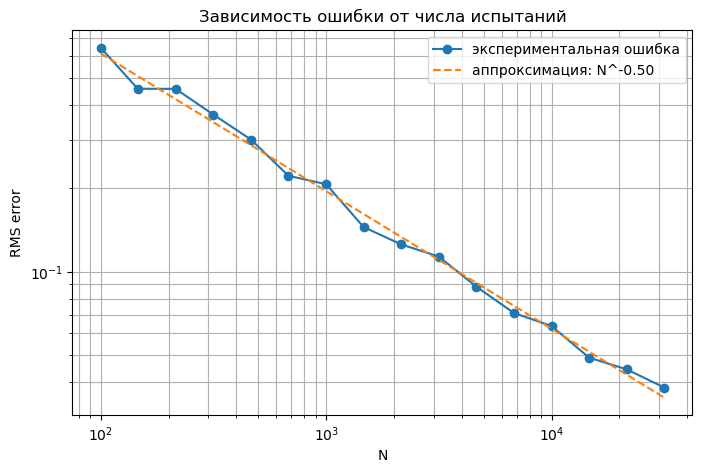

In [8]:
def mc_estimates(T, N, M, rng):
    k = rng.binomial(T, 0.5, size=(M, N))
    distances = np.abs(2 * k - T)
    return distances.mean(axis=1)


N_values = np.unique(np.logspace(2, 4.5, 16).astype(int))
M = 200

errors = []

for n in N_values:
    estimates = mc_estimates(T, n, M, rng)
    error = np.sqrt(np.mean((estimates - exact_value) ** 2))
    errors.append(error)

errors = np.array(errors)

slope, intercept = np.polyfit(np.log(N_values), np.log(errors), 1)

print(f"slope = {slope:.3f}")

plt.figure(figsize=(8, 5))

plt.loglog(N_values, errors, "o-", label="экспериментальная ошибка")
plt.loglog(
    N_values,
    np.exp(intercept) * N_values**slope,
    "--",
    label=f"аппроксимация: N^{slope:.2f}"
)

plt.xlabel("N")
plt.ylabel("RMS error")
plt.title("Зависимость ошибки от числа испытаний")
plt.grid(True, which="both")
plt.legend()

plt.show()

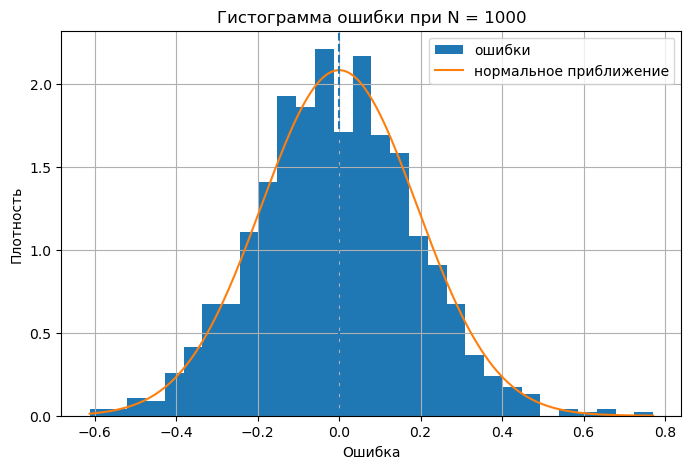

In [9]:
N_hist = 1000
M_hist = 1000

estimates_hist = mc_estimates(T, N_hist, M_hist, rng)
hist_errors = estimates_hist - exact_value

sigma = np.sqrt((T - exact_value**2) / N_hist)
xs = np.linspace(hist_errors.min(), hist_errors.max(), 300)
normal_density = 1 / np.sqrt(2 * np.pi * sigma**2) * np.exp(-xs**2 / (2 * sigma**2))

plt.figure(figsize=(8, 5))

plt.hist(hist_errors, bins=30, density=True, label="ошибки")
plt.plot(xs, normal_density, label="нормальное приближение")
plt.axvline(0, linestyle="--")

plt.xlabel("Ошибка")
plt.ylabel("Плотность")
plt.title(f"Гистограмма ошибки при N = {N_hist}")
plt.grid(True)
plt.legend()

plt.show()

### Вывод

Аналитически математическое ожидание расстояния после $T$ шагов равно

$E|S_T| = \sum_{k=0}^{T} |2k - T| \cdot \frac{C_T^k}{2^T}$.

Для больших $T$ это значение хорошо приближается формулой

$E|S_T| \approx \sqrt{\frac{2T}{\pi}}$.

Численное моделирование методом Монте-Карло дало значение, близкое к аналитическому. На логарифмическом графике ошибка убывает примерно как $N^{-1/2}$. Это согласуется с общей сходимостью метода Монте-Карло, где погрешность имеет порядок $1/\sqrt{N}$. Гистограмма ошибки похожа на нормальное распределение, что также согласуется с центральной предельной теоремой.

## Задание 4. Семплирование по Гиббсу

Семплируйте по Гиббсу сумму двух гауссианов из разобранного примера на алгоритм Метрополиса-Хастингса.

In [10]:
weights = np.array([0.4, 0.6])

means = np.array([
    [0.0, 0.0],
    [-2.0, -2.0]
])

variances = np.array([
    [1.0, 1.0],
    [1.5, 0.5]
])

rng = np.random.default_rng(1337)

In [11]:
def normal_pdf_1d(x, mean, var):
    return 1 / np.sqrt(2 * np.pi * var) * np.exp(-(x - mean) ** 2 / (2 * var))


def normal_pdf_2d_diag(x, y, mean, var):
    px = normal_pdf_1d(x, mean[0], var[0])
    py = normal_pdf_1d(y, mean[1], var[1])
    return px * py


def mixture_pdf(x, y):
    ans = 0

    for k in range(2):
        ans += weights[k] * normal_pdf_2d_diag(x, y, means[k], variances[k])

    return ans

def component_probs(value, coord):
    probs = np.zeros(2)

    for k in range(2):
        probs[k] = weights[k] * normal_pdf_1d(
            value,
            means[k, coord],
            variances[k, coord]
        )

    return probs / probs.sum()

def gibbs_sampler(N, burn_in=1000, thin=1):
    total_steps = burn_in + N * thin

    samples = np.zeros((N, 2))
    x, y = 0.0, 0.0
    j = 0

    for i in range(total_steps):
        probs_x = component_probs(y, coord=1)
        c = rng.choice(2, p=probs_x)
        x = rng.normal(means[c, 0], np.sqrt(variances[c, 0]))

        probs_y = component_probs(x, coord=0)
        c = rng.choice(2, p=probs_y)
        y = rng.normal(means[c, 1], np.sqrt(variances[c, 1]))

        if i >= burn_in and (i - burn_in) % thin == 0:
            samples[j] = [x, y]
            j += 1

    return samples

[[-4.23250338 -2.57370479]
 [-2.40835516 -1.98642702]
 [-3.31085559 -2.53730238]
 [-1.54576147 -2.36934866]
 [-2.66215691 -1.48426242]]


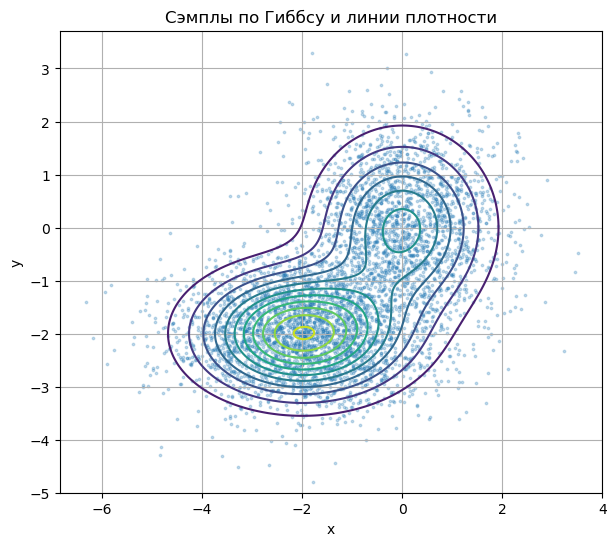

In [12]:
N = 50000

samples = gibbs_sampler(N, burn_in=2000, thin=2)

print(samples[:5])

plt.figure(figsize=(7, 6))

x_grid = np.linspace(-6, 4, 200)
y_grid = np.linspace(-5, 3, 200)
X, Y = np.meshgrid(x_grid, y_grid)
Z = mixture_pdf(X, Y)

plt.contour(X, Y, Z, levels=12)
plt.scatter(samples[:5000, 0], samples[:5000, 1], s=3, alpha=0.25)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Сэмплы по Гиббсу и линии плотности")
plt.grid(True)

plt.show()

## Задание 5. Алгоритм Метрополиса-Хастингса - генерация выборок

Сгенерируйте выборку из функции плотности 

$$\pi(x) \sim \exp(-x^2)(3 + \cos(x) + 2\sin(x) + x^2)$$

применив алгоритм Метрополиса-Хастингса к случайному блужданию $x_{t+1} = x_t + \varepsilon_t$ где $\varepsilon_t \sim N(0, 1)$.

In [13]:
def log_pi(x):
    return -x**2 + np.log(3 + np.cos(x) + 2 * np.sin(x) + x**2)

def metropolis_hastings(N, x0=0.0, burn_in=5000, thin=5):
    total_steps = burn_in + N * thin

    x = x0
    samples = np.zeros(N)
    accepted = 0
    j = 0

    for i in range(total_steps):
        x_new = x + rng.normal(0, 1)

        log_a = log_pi(x_new) - log_pi(x)

        if np.log(rng.random()) < min(0, log_a):
            x = x_new
            accepted += 1

        if i >= burn_in and (i - burn_in) % thin == 0:
            samples[j] = x
            j += 1

    return samples, accepted / total_steps

Доля принятых кандидатов: 0.6134
Среднее по выборке: 0.1819
Дисперсия по выборке: 0.5380


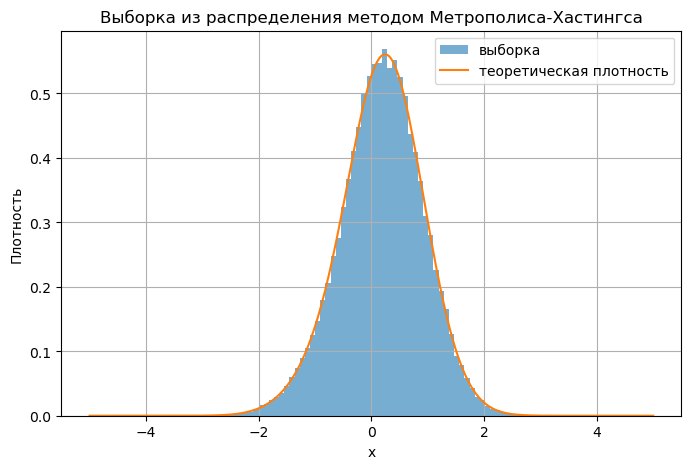

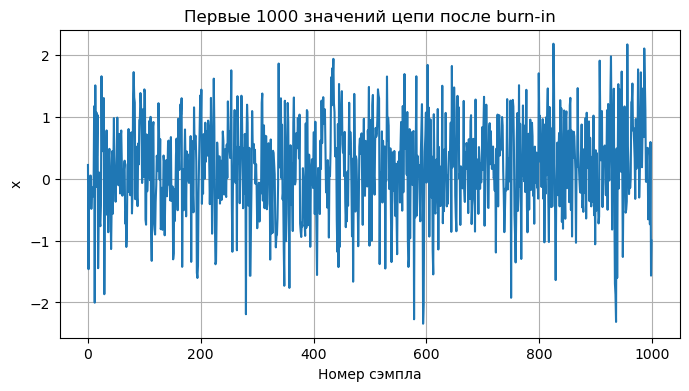

In [14]:

rng = np.random.default_rng(1337)
N = 100000
samples, accept_rate = metropolis_hastings(N)

print(f"Доля принятых кандидатов: {accept_rate:.4f}")
print(f"Среднее по выборке: {samples.mean():.4f}")
print(f"Дисперсия по выборке: {samples.var():.4f}")


x_grid = np.linspace(-5, 5, 1000)
unnormalized = np.exp(log_pi(x_grid))
normalization = np.trapezoid(unnormalized, x_grid)
density = unnormalized / normalization

plt.figure(figsize=(8, 5))
plt.hist(samples, bins=70, density=True, alpha=0.6, label="выборка")
plt.plot(x_grid, density, label="теоретическая плотность")
plt.xlabel("x")
plt.ylabel("Плотность")
plt.title("Выборка из распределения методом Метрополиса-Хастингса")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(samples[:1000])
plt.xlabel("Номер сэмпла")
plt.ylabel("x")
plt.title("Первые 1000 значений цепи после burn-in")
plt.grid(True)
plt.show()